In [1]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

emails = ["Selamat Anda mendapatkan hadiah besar!",
        "Jangan lewatkan penawaran eksklusif ini.",
        "Email ini tidak penting dan hanya spam."]

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(emails)
tfidf = X.toarray()

features = vectorizer.get_feature_names_out()
print("Fitur-fitur dari teks tersebut adalah: \n", features)

print(" ")
print("Hasil dari Matriks TF-IDF adalah: ")
print("Kolom = Fitur, Baris = Dokumen \n", tfidf)
print("\nKolom = Dokumen, Baris = Fitur\n", tfidf.T)

df_tfidf = pd.DataFrame(tfidf, columns=features)

df_tfidf.to_csv('tfidf_matrix.csv', index=False)

df_tfidf_transpose = pd.DataFrame(tfidf.T, index=features)

df_tfidf_transpose.columns = [f'Dokumen {i+1}' for i in range(len(emails))]

df_tfidf_transpose.to_csv('tfidf_matrix_transposed.csv', index=True)

Fitur-fitur dari teks tersebut adalah: 
 ['anda' 'besar' 'dan' 'eksklusif' 'email' 'hadiah' 'hanya' 'ini' 'jangan'
 'lewatkan' 'mendapatkan' 'penawaran' 'penting' 'selamat' 'spam' 'tidak']
 
Hasil dari Matriks TF-IDF adalah: 
Kolom = Fitur, Baris = Dokumen 
 [[0.4472136  0.4472136  0.         0.         0.         0.4472136
  0.         0.         0.         0.         0.4472136  0.
  0.         0.4472136  0.         0.        ]
 [0.         0.         0.         0.46735098 0.         0.
  0.         0.35543247 0.46735098 0.46735098 0.         0.46735098
  0.         0.         0.         0.        ]
 [0.         0.         0.38988801 0.         0.38988801 0.
  0.38988801 0.29651988 0.         0.         0.         0.
  0.38988801 0.         0.38988801 0.38988801]]

Kolom = Dokumen, Baris = Fitur
 [[0.4472136  0.         0.        ]
 [0.4472136  0.         0.        ]
 [0.         0.         0.38988801]
 [0.         0.46735098 0.        ]
 [0.         0.         0.38988801]
 [0.4472136

In [2]:
doc1 = 'Saya suka belajar pemrograman Python. Python sangat menarik!'
doc2 = 'Python sangat bermanfaat untuk pembelajaran mesin. Saya suka belajar Python.'
doc3 = 'Saya suka bepergian dan menjelajah tempat baru. Bepergian sangat menyenangkan!'

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [doc1, doc2, doc3]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

print("Kata-kata dalam dokumen: \n", vectorizer.get_feature_names_out())
print("\n TF-IDF Matriks:")
print(tfidf_matrix.toarray())

Kata-kata dalam dokumen: 
 ['baru' 'belajar' 'bepergian' 'bermanfaat' 'dan' 'menarik' 'menjelajah'
 'menyenangkan' 'mesin' 'pembelajaran' 'pemrograman' 'python' 'sangat'
 'saya' 'suka' 'tempat' 'untuk']

 TF-IDF Matriks:
[[0.         0.31208745 0.         0.         0.         0.4103575
  0.         0.         0.         0.         0.4103575  0.62417491
  0.24236375 0.24236375 0.24236375 0.         0.        ]
 [0.         0.26992635 0.         0.35492071 0.         0.
  0.         0.         0.35492071 0.35492071 0.         0.53985269
  0.20962189 0.20962189 0.20962189 0.         0.35492071]
 [0.31549537 0.         0.63099074 0.         0.31549537 0.
  0.31549537 0.31549537 0.         0.         0.         0.
  0.18633665 0.18633665 0.18633665 0.31549537 0.        ]]


In [4]:
from sklearn.metrics.pairwise import cosine_similarity

cos_sim_matrix = cosine_similarity(tfidf_matrix, tfidf_matrix)

print('Cosine Similarity Matrix:')
print(cos_sim_matrix)

Cosine Similarity Matrix:
[[1.         0.57361737 0.13548375]
 [0.57361737 1.         0.11718072]
 [0.13548375 0.11718072 1.        ]]


In [5]:
from sklearn.metrics import confusion_matrix

y_true = [0, 1, 1, 0, 1]
y_pred = [0, 1, 0, 0, 1]

cm = confusion_matrix(y_true, y_pred)
print(cm)

[[2 0]
 [1 2]]


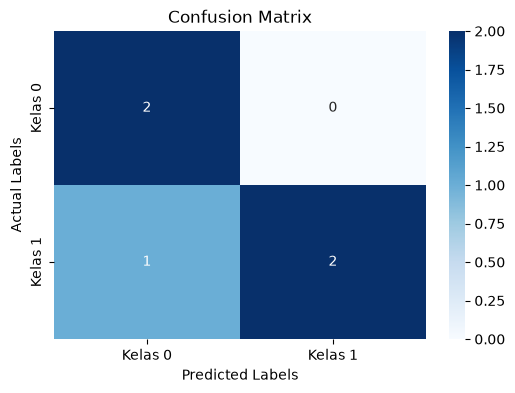

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

cm = np.array([[2, 0],
                [1, 2]])

labels = ['Kelas 0', 'Kelas 1']

plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Labels')
plt.ylabel('Actual Labels')
plt.show()

In [7]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(y_true, y_pred)
recall = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print(f"Akurasi: {accuracy:.2f}")
print(f"Presisi: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1-Score: {f1:.2f}")

Akurasi: 0.80
Presisi: 1.00
Recall: 0.67
F1-Score: 0.80


In [8]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

documents = [
    "Saya suka belajar data science.",
    "Data science adalah bidang yang menarik.",
    "Belajar machine learning itu menyenangkan.",
    "Data membuat hidup lebih mudah."
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

df_tfidf = pd.DataFrame(tfidf_matrix.toarray(), columns=vectorizer.get_feature_names_out())

df_tfidf_sorted = df_tfidf.sort_values(by="data", ascending=True)

print("TF-IDF Matrix:")
print(df_tfidf_sorted)

TF-IDF Matrix:
     adalah   belajar    bidang      data    hidup       itu  learning  \
2  0.000000  0.366739  0.000000  0.000000  0.00000  0.465162  0.465162   
1  0.445922  0.000000  0.445922  0.284626  0.00000  0.000000  0.000000   
3  0.000000  0.000000  0.000000  0.304035  0.47633  0.000000  0.000000   
0  0.000000  0.412640  0.000000  0.334067  0.00000  0.000000  0.000000   

     lebih   machine  membuat   menarik  menyenangkan    mudah      saya  \
2  0.00000  0.465162  0.00000  0.000000      0.465162  0.00000  0.000000   
1  0.00000  0.000000  0.00000  0.445922      0.000000  0.00000  0.000000   
3  0.47633  0.000000  0.47633  0.000000      0.000000  0.47633  0.000000   
0  0.00000  0.000000  0.00000  0.000000      0.000000  0.00000  0.523381   

   science      suka      yang  
2  0.00000  0.000000  0.000000  
1  0.35157  0.000000  0.445922  
3  0.00000  0.000000  0.000000  
0  0.41264  0.523381  0.000000  


In [ ]:
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

documents = [
    "Saya suka belajar pemrograman.",
    "Pemrograman sangat menyenangkan.",
    "Belajar adalah kunci untuk sukses.",
    "Saya tidak suka kucing."
]

vectorizer = TfidfVectorizer()
tfidf_matrix = vectorizer.fit_transform(documents)

df_tfidf = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=vectorizer.get_feature_names_out()
)

print("TF-IDF Matrix:")
print(df_tfidf)

similarity = cosine_similarity(tfidf_matrix)

similarity_df = pd.DataFrame(
    similarity,
    index=range(1, len(documents) + 1),
    columns=range(1, len(documents) + 1)
)

print("\nCosine Similarity Matrix:")
print(similarity_df)

doc1_doc2_similarity = similarity_df.iloc[0, 1]

print(
    f"\nCosine Similarity antara Dokumen 1 dan Dokumen 2: "
    f"{doc1_doc2_similarity}"
)

TF-IDF Matrix:
     adalah   belajar    kucing     kunci  menyenangkan  pemrograman  \
0  0.000000  0.500000  0.000000  0.000000      0.000000     0.500000   
1  0.000000  0.000000  0.000000  0.000000      0.617614     0.486934   
2  0.465162  0.366739  0.000000  0.465162      0.000000     0.000000   
3  0.000000  0.000000  0.555283  0.000000      0.000000     0.000000   

     sangat      saya      suka    sukses     tidak     untuk  
0  0.000000  0.500000  0.500000  0.000000  0.000000  0.000000  
1  0.617614  0.000000  0.000000  0.000000  0.000000  0.000000  
2  0.000000  0.000000  0.000000  0.465162  0.000000  0.465162  
3  0.000000  0.437791  0.437791  0.000000  0.555283  0.000000  

Cosine Similarity Matrix:
          1         2        3         4
1  1.000000  0.243467  0.18337  0.437791
2  0.243467  1.000000  0.00000  0.000000
3  0.183370  0.000000  1.00000  0.000000
4  0.437791  0.000000  0.00000  1.000000

Cosine Similarity antara Dokumen 1 dan Dokumen 2: 0.1833695056487086
